# E.1 Split, drift, and exchange

Two daughter populations inherit allele copies from a common source. Why do their frequencies separate, and what does migration do to that difference?

After a split, finite sampling can move the frequencies apart even when neither allele affects fitness. With symmetric migration fraction $m$, first mix expected frequencies:

$$p_1^*=(1-m)p_1+mp_2,\qquad p_2^*=(1-m)p_2+mp_1.$$

Then draw new counts, $K'_k\mid p_k^*\sim\operatorname{Binomial}(2N_e,p_k^*)$. Without sampling noise, the gap contracts by $1-2m$ per generation. Sampling makes realized gaps scatter around that expectation.


## Drift after a split

Start both populations at frequency 0.5 with no migration. Their average difference should remain near zero, while the absolute difference grows in many independent pairs. This is drift creating differentiation without a fixed direction.


In [1]:
library(hpgR)

set.seed(1010)
generations <- 30
split_pairs <- replicate(100, simulateMigrationDrift(c(0.5, 0.5), 100, 0, generations),
                         simplify = FALSE)
split_gap <- sapply(split_pairs, function(x) x[, 1] - x[, 2])
stopifnot(all(abs(split_gap) <= 1))


## Migration against drift

Now use the lecture's two frequencies, $p_1=0.8$ and $p_2=0.2$, with $m=0.05$. Without drift, the expected gap after $t$ generations is $0.6(1-2m)^t$. We expect the mean of many finite-population paths to follow this line approximately, while individual paths wander.


mean_final_gap model_final_gap 
     0.01590000      0.02543469

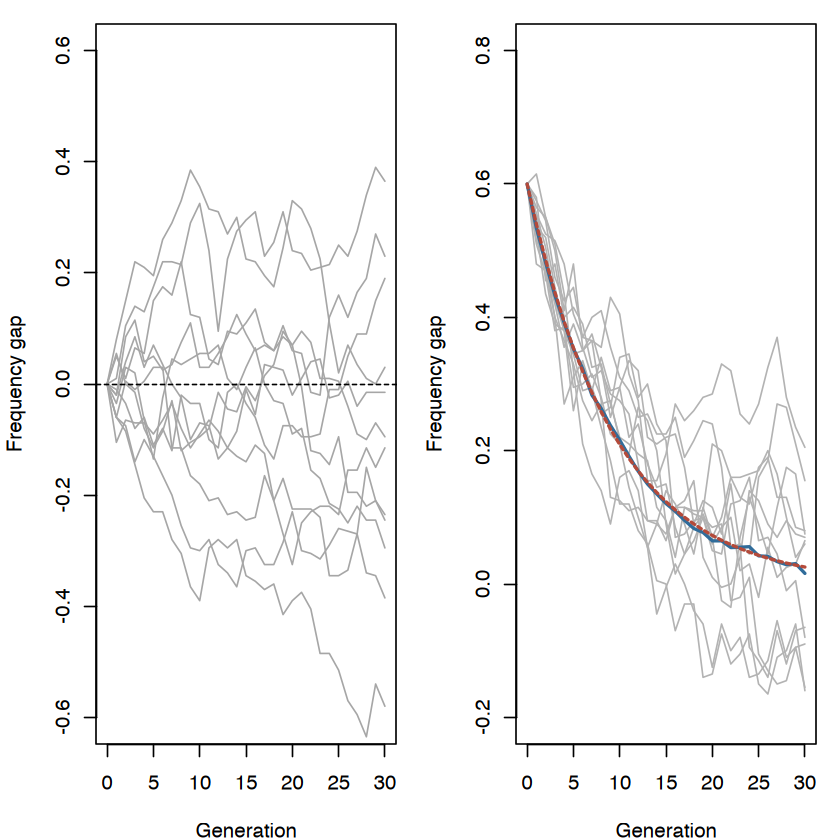

In [2]:
m <- 0.05
migration_pairs <- replicate(100, simulateMigrationDrift(c(0.8, 0.2), 100, m, generations),
                             simplify = FALSE)
migration_gap <- sapply(migration_pairs, function(x) x[, 1] - x[, 2])
time <- 0:generations
expected_gap <- 0.6 * (1 - 2 * m)^time
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 1, 1))
matplot(time, split_gap[, 1:12], type = 'l', lty = 1, col = 'grey65',
        ylim = c(-0.6, 0.6), xlab = 'Generation', ylab = 'Frequency gap')
abline(h = 0, lty = 2)
plot(time, migration_gap[, 1], type = 'l', col = 'grey70',
     ylim = c(-0.2, 0.8), xlab = 'Generation', ylab = 'Frequency gap')
for (j in 2:12) lines(time, migration_gap[, j], col = 'grey70')
lines(time, rowMeans(migration_gap), col = '#306C9A', lwd = 2)
lines(time, expected_gap, col = '#B44A3A', lwd = 2, lty = 2)
par(old_par)
c(mean_final_gap = mean(migration_gap[31, ]),
  model_final_gap = expected_gap[31])


## What to remember

Drift changes allele frequencies through binomial sampling; migration mixes copies between populations. The deterministic recursion predicts an average tendency, not a guaranteed path. The example holds population sizes equal and migration symmetric, so its contraction factor does not apply to every history.

**Sources.** Pritchard, *An Owner's Guide to the Human Genome*, Sections 2.1 and 2.4; Gorroochurn, *Population Genetics Notes*, Sections 8.2 and 9.2–9.4. The model follows the lecture; the 100 replicate pairs are original simulations (seed 1010, $N_e=100$). The $0.8/0.2$ start matches the lecture.
